# Analyze a SIMBA spatial (PPP) line-emission cube

Analyze `output_line_cube_ppp.npz` using only NumPy and Matplotlib; no HPC access, snapshot, catalogue, or emissivity table is required. Run the cells in order. The file path and plotting options are editable in the first cell.

**Convention:** `cube_erg_s[z, y, x]` is intrinsic luminosity per voxel, not a spectrum. The z axis is spatial. The saved volume emissivity is luminosity divided by the **full voxel volume**, including any empty volume, not the emitting particles' own emissivity.

Maps below show intrinsic projected luminosity per physical area. They do not include distance conversion, cosmological dimming, dust, or an instrument model. Pipeline coordinates are already offsets from the saved object center.


In [1]:
from pathlib import Path
import warnings

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "font.size": 10})

# Set a path explicitly, or leave None to search the working directory and its parents.
CUBE_PATH = None
CUBE_FILENAME = "output_line_cube_ppp.npz"
SAVE_FIGURES = False  # If True, save figures beside the input cube.
PROFILE_CENTER_OFFSET_KPC = np.array([0.0, 0.0, 0.0])
N_RADIAL_BINS = 15

if CUBE_PATH is None:
    candidates = [parent / CUBE_FILENAME for parent in (Path.cwd(), *Path.cwd().parents)]
    matches = [path for path in candidates if path.is_file()]
    if not matches:
        raise FileNotFoundError(f"Cannot locate {CUBE_FILENAME}; set CUBE_PATH explicitly.")
    cube_path = matches[0]
else:
    cube_path = Path(CUBE_PATH).expanduser()
    if not cube_path.is_file():
        raise FileNotFoundError(cube_path)
cube_path = cube_path.resolve()
figure_dir = cube_path.parent / "ppp_analysis_figures"

def scalar(key, default=None):
    """Read a saved scalar without enabling pickle loading.

    Returns: data_output (object): Python scalar, or default if the key is absent.
    """
    if key not in data:
        return default
    value = np.asarray(data[key])
    if value.ndim != 0:
        raise ValueError(f"{key} should be a scalar, got shape {value.shape}.")
    return value.item()

def finish_figure(fig, name):
    """Optionally export a figure, then display it inline.

    Returns: data_output (None): the figure is displayed and optionally saved.
    """
    if SAVE_FIGURES:
        figure_dir.mkdir(parents=True, exist_ok=True)
        destination = figure_dir / f"{cube_path.stem}_{name}.png"
        fig.savefig(destination, dpi=180, bbox_inches="tight")
        print("Saved:", destination)
    plt.show()

with np.load(cube_path, allow_pickle=False) as archive:
    data = {key: archive[key] for key in archive.files}
print("Input:", cube_path)
print("Available arrays:", ", ".join(data))


Input: /Users/jiaheak/projects/Codex_SIMBA/output_line_cube_ppp.npz
Available arrays: cube_erg_s, volume_emissivity_erg_s_cm3, voxel_volume_cm3, x_edges_kpc, y_edges_kpc, z_edges_kpc, cube_axis_order, input_particle_count, included_particle_count, excluded_particle_count, input_luminosity_erg_s, included_luminosity_erg_s, excluded_luminosity_erg_s, input_source, cube_type, table_type, line_label, redshift, selected_particle_count, center_kpc, box_size_kpc, config_filename, snapshot_filename, catalogue_filename, group_type, target_index


## 1. Validate geometry, units, and saved accounting

Check the PPP axis order, finite/nonnegative luminosities, edge arrays, physical voxel volumes, and the relation between luminosity and spatially averaged emissivity. The same validation supports unequal spatial bin widths.

The coverage report compares the saved grid with the upstream selected-particle sample. Luminosity outside the grid cannot be recovered from this cube.


In [2]:
required = {
    "cube_erg_s", "volume_emissivity_erg_s_cm3", "voxel_volume_cm3",
    "x_edges_kpc", "y_edges_kpc", "z_edges_kpc", "cube_axis_order", "cube_type",
}
missing = required - set(data)
if missing:
    raise KeyError(f"Required PPP arrays are missing: {sorted(missing)}")
if scalar("cube_type") != "ppp" or scalar("cube_axis_order") != "z,y,x":
    raise ValueError("This notebook requires a PPP cube saved in (z, y, x) order.")

cube = np.asarray(data["cube_erg_s"], dtype=float)
emissivity = np.asarray(data["volume_emissivity_erg_s_cm3"], dtype=float)
voxel_volume = np.asarray(data["voxel_volume_cm3"], dtype=float)
edges = {axis: np.asarray(data[f"{axis}_edges_kpc"], dtype=float) for axis in "xyz"}
for axis, values in edges.items():
    if (values.ndim != 1 or values.size < 2 or not np.all(np.isfinite(values))
            or not np.all(np.diff(values) > 0)):
        raise ValueError(f"{axis} edges must be finite and strictly increasing.")
expected_shape = tuple(edges[axis].size - 1 for axis in "zyx")
for name, values in (("luminosity", cube), ("emissivity", emissivity), ("volume", voxel_volume)):
    if values.shape != expected_shape or not np.all(np.isfinite(values)):
        raise ValueError(f"Invalid {name} cube shape/values: {values.shape}.")
    if np.any(values < 0) or (name == "volume" and np.any(values <= 0)):
        raise ValueError(f"Invalid negative or zero {name} values.")

widths = {axis: np.diff(values) for axis, values in edges.items()}
centers = {axis: 0.5 * (values[:-1] + values[1:]) for axis, values in edges.items()}
KPC_TO_CM = 3.0856775814913673e21
expected_volume = (
    widths["z"][:, None, None] * widths["y"][None, :, None]
    * widths["x"][None, None, :] * KPC_TO_CM**3
)
np.testing.assert_allclose(voxel_volume, expected_volume, rtol=1e-10, atol=0)
np.testing.assert_allclose(emissivity, cube / voxel_volume, rtol=1e-10, atol=0)

total_L = float(cube.sum())
line_label = str(scalar("line_label", "unspecified line"))
for key in ("line_label", "table_type", "input_source", "redshift", "group_type",
            "target_index", "selected_particle_count"):
    print(f"{key}: {scalar(key, 'not saved')}")
print("Saved center in physical kpc:", data.get("center_kpc", "not saved"))
print("Array shape (z, y, x):", cube.shape)
for axis in "xyz":
    print(f"{axis}: [{edges[axis][0]:g}, {edges[axis][-1]:g}] physical kpc; "
          f"bin widths [{widths[axis].min():.4g}, {widths[axis].max():.4g}] kpc")
print(f"Luminosity inside grid: {total_L:.6e} erg/s")
print(f"Emitting voxels: {np.count_nonzero(cube):,} / {cube.size:,} "
      f"({np.count_nonzero(cube) / cube.size:.2%})")

count_keys = ("input_particle_count", "included_particle_count", "excluded_particle_count")
if all(key in data for key in count_keys):
    n_input, n_inside, n_outside = [int(scalar(key)) for key in count_keys]
    if n_input != n_inside + n_outside:
        raise ValueError("Saved particle-count accounting is inconsistent.")
    print(f"Particles inside/outside grid: {n_inside:,} / {n_outside:,} "
          f"(input total: {n_input:,})")
    if n_input:
        print(f"Particle coverage: {n_inside / n_input:.3%}")
lum_keys = ("input_luminosity_erg_s", "included_luminosity_erg_s", "excluded_luminosity_erg_s")
if all(key in data for key in lum_keys):
    L_input, L_inside, L_outside = [float(scalar(key)) for key in lum_keys]
    np.testing.assert_allclose(total_L, L_inside, rtol=1e-10, atol=0)
    np.testing.assert_allclose(L_input, L_inside + L_outside, rtol=1e-10, atol=0)
    print(f"Input / excluded luminosity: {L_input:.6e} / {L_outside:.6e} erg/s")
    if L_input > 0:
        print(f"Luminosity coverage: {L_inside / L_input:.3%}")
if total_L == 0:
    warnings.warn("The cube is all zero; plots will explicitly display no emission.")
print("Geometry, emissivity normalization, and available accounting checks passed.")


line_label: O  8 18.9689A
table_type: cloudy_hdf5
input_source: simba
redshift: 4.440892098500626e-16
group_type: halo
target_index: 0
selected_particle_count: 2377715
Saved center in physical kpc: [37422.70220588 45422.05882353 54819.74954044]
Array shape (z, y, x): (60, 60, 60)
x: [-100, 100] physical kpc; bin widths [3.333, 3.333] kpc
y: [-100, 100] physical kpc; bin widths [3.333, 3.333] kpc
z: [-100, 100] physical kpc; bin widths [3.333, 3.333] kpc
Luminosity inside grid: 1.004897e+41 erg/s
Emitting voxels: 35,885 / 216,000 (16.61%)
Particles inside/outside grid: 36,075 / 2,341,640 (input total: 2,377,715)
Particle coverage: 1.517%
Input / excluded luminosity: 1.894461e+42 / 1.793972e+42 erg/s
Luminosity coverage: 5.304%
Geometry, emissivity normalization, and available accounting checks passed.


## 2. Three orthogonal projected maps

Sum luminosity over the spatial line of sight and divide by each projected pixel's physical area. **Do not multiply the luminosity cube by voxel depth:** its values are already integrated over each voxel.

All three maps share one color scale. Zeros are explicitly masked in logarithmic plots. The color represents erg/s/kpc² (intrinsic luminosity surface density), not observed flux per arcsec².


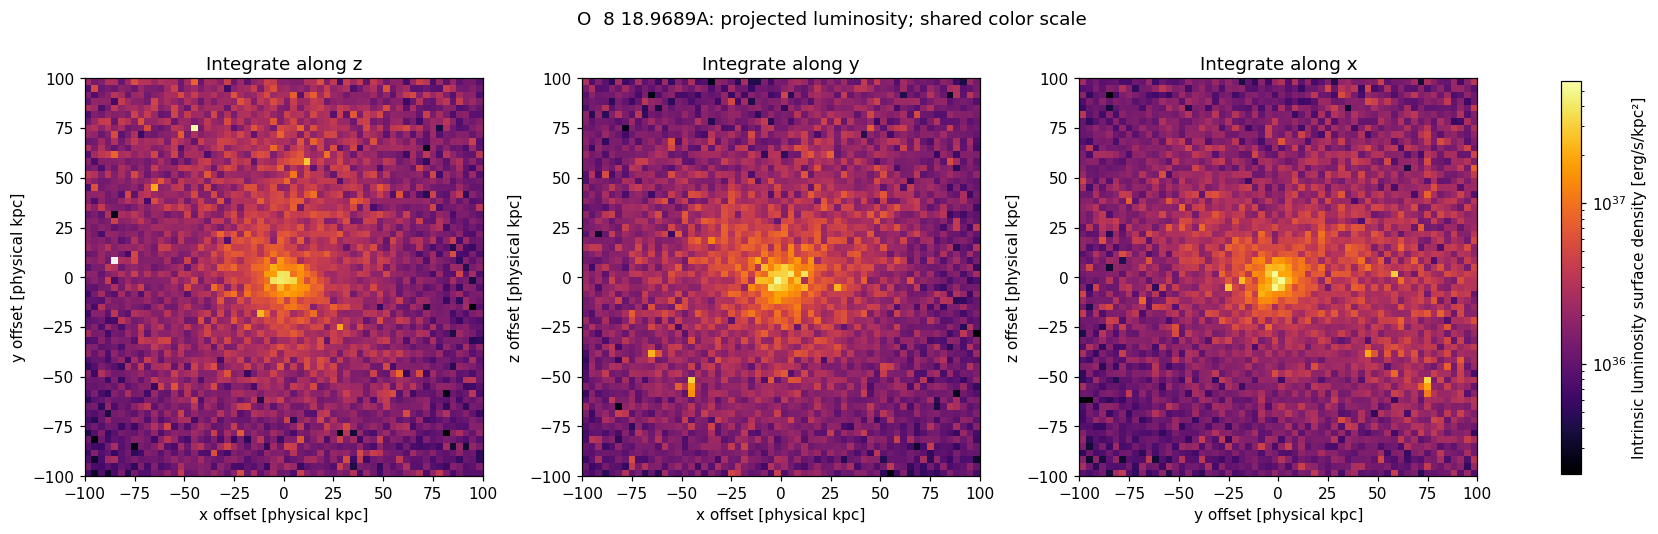

In [3]:
def shared_norm(images):
    """Build a common log scale for positive values, or a zero-safe linear scale.

    Returns: data_output (matplotlib.colors.Normalize): shared image normalization.
    """
    positive = [np.asarray(image)[np.asarray(image) > 0] for image in images
                if np.any(np.asarray(image) > 0)]
    if not positive:
        return Normalize(vmin=0, vmax=1)
    vmin = min(values.min() for values in positive)
    vmax = max(values.max() for values in positive)
    if vmin == vmax:
        vmin, vmax = 0.5 * vmin, 2.0 * vmax
    return LogNorm(vmin=vmin, vmax=vmax)

def draw_map(ax, image, horizontal_edges, vertical_edges, norm, title, axes_names):
    """Plot an image using its actual spatial edges.

    Returns: data_output (matplotlib.collections.QuadMesh): image for a colorbar.
    """
    image_to_plot = np.ma.masked_less_equal(image, 0) if isinstance(norm, LogNorm) else image
    mesh = ax.pcolormesh(horizontal_edges, vertical_edges, image_to_plot,
                         shading="flat", cmap="inferno", norm=norm, rasterized=True)
    ax.set(xlabel=f"{axes_names[0]} offset [physical kpc]",
           ylabel=f"{axes_names[1]} offset [physical kpc]", title=title)
    ax.set_aspect("equal")
    ax.set_facecolor("0.94")
    if not np.any(image > 0):
        ax.text(0.5, 0.5, "No positive emission", transform=ax.transAxes, ha="center")
    return mesh

projection_L = {
    "xy": cube.sum(axis=0),  # sum z -> (y, x)
    "xz": cube.sum(axis=1),  # sum y -> (z, x)
    "yz": cube.sum(axis=2),  # sum x -> (z, y)
}
projection_area = {
    "xy": widths["y"][:, None] * widths["x"][None, :],
    "xz": widths["z"][:, None] * widths["x"][None, :],
    "yz": widths["z"][:, None] * widths["y"][None, :],
}
surface_density = {plane: projection_L[plane] / projection_area[plane]
                   for plane in projection_L}
for image in projection_L.values():
    np.testing.assert_allclose(image.sum(), total_L, rtol=1e-10, atol=0)

norm = shared_norm(list(surface_density.values()))
fig, axs = plt.subplots(1, 3, figsize=(15, 4.8), constrained_layout=True)
for ax, plane, los in zip(axs, ("xy", "xz", "yz"), ("z", "y", "x")):
    horizontal, vertical = plane
    mesh = draw_map(ax, surface_density[plane], edges[horizontal], edges[vertical],
                    norm, f"Integrate along {los}", (horizontal, vertical))
fig.colorbar(mesh, ax=axs.tolist(), label="Intrinsic luminosity surface density [erg/s/kpc²]", shrink=0.82)
fig.suptitle(f"{line_label}: projected luminosity; shared color scale")
finish_figure(fig, "orthogonal_projections")


## 3. Central orthogonal slices

These are one-voxel-thick slices of **spatially averaged volume emissivity** (erg/s/cm³), unlike the depth-integrated maps above. Edit `SLICE_POSITION_KPC` to move each plane. When a requested position is a bin edge, use the bin to its right (the final upper edge uses the last bin). The actual bin center is printed.


x slice bin center: 1.667 physical kpc
y slice bin center: 1.667 physical kpc
z slice bin center: 1.667 physical kpc


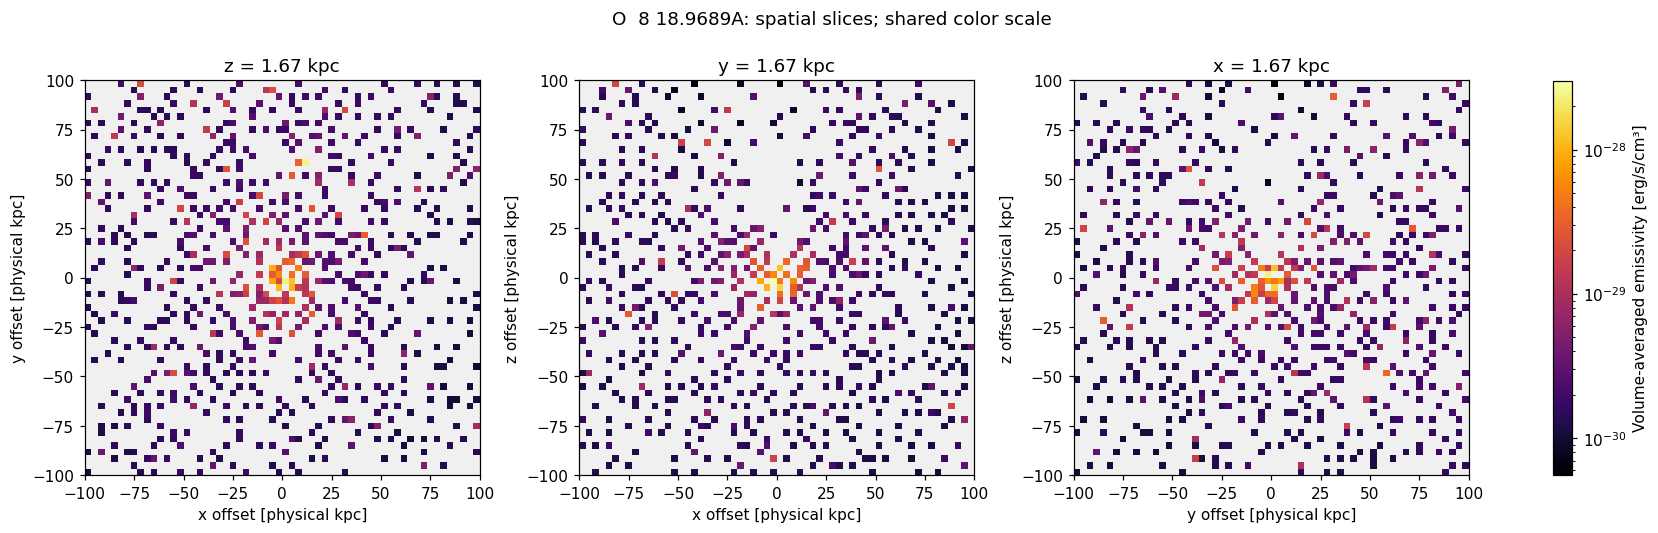

In [4]:
SLICE_POSITION_KPC = {"x": 0.0, "y": 0.0, "z": 0.0}

slice_indices = {}
for axis in "xyz":
    position = float(SLICE_POSITION_KPC[axis])
    if not edges[axis][0] <= position <= edges[axis][-1]:
        raise ValueError(f"Requested {axis} slice is outside the saved grid.")
    index = int(np.searchsorted(edges[axis], position, side="right") - 1)
    if index == centers[axis].size:
        index -= 1
    slice_indices[axis] = index
    print(f"{axis} slice bin center: {centers[axis][index]:.4g} physical kpc")
slices = {
    "xy": emissivity[slice_indices["z"], :, :],
    "xz": emissivity[:, slice_indices["y"], :],
    "yz": emissivity[:, :, slice_indices["x"]],
}
norm = shared_norm(list(slices.values()))
fig, axs = plt.subplots(1, 3, figsize=(15, 4.8), constrained_layout=True)
for ax, plane, fixed in zip(axs, ("xy", "xz", "yz"), ("z", "y", "x")):
    horizontal, vertical = plane
    actual_position = centers[fixed][slice_indices[fixed]]
    mesh = draw_map(ax, slices[plane], edges[horizontal], edges[vertical], norm,
                    f"{fixed} = {actual_position:.2f} kpc", (horizontal, vertical))
fig.colorbar(mesh, ax=axs.tolist(), label="Volume-averaged emissivity [erg/s/cm³]", shrink=0.82)
fig.suptitle(f"{line_label}: spatial slices; shared color scale")
finish_figure(fig, "orthogonal_slices")


## 4. Luminosity profiles along x, y, and z

Sum over the other two coordinates and divide by each spatial bin width to obtain dL/ds. Integrating these profiles with the bin widths recovers the luminosity inside the full saved cube. A PPP cube has no velocity profile.


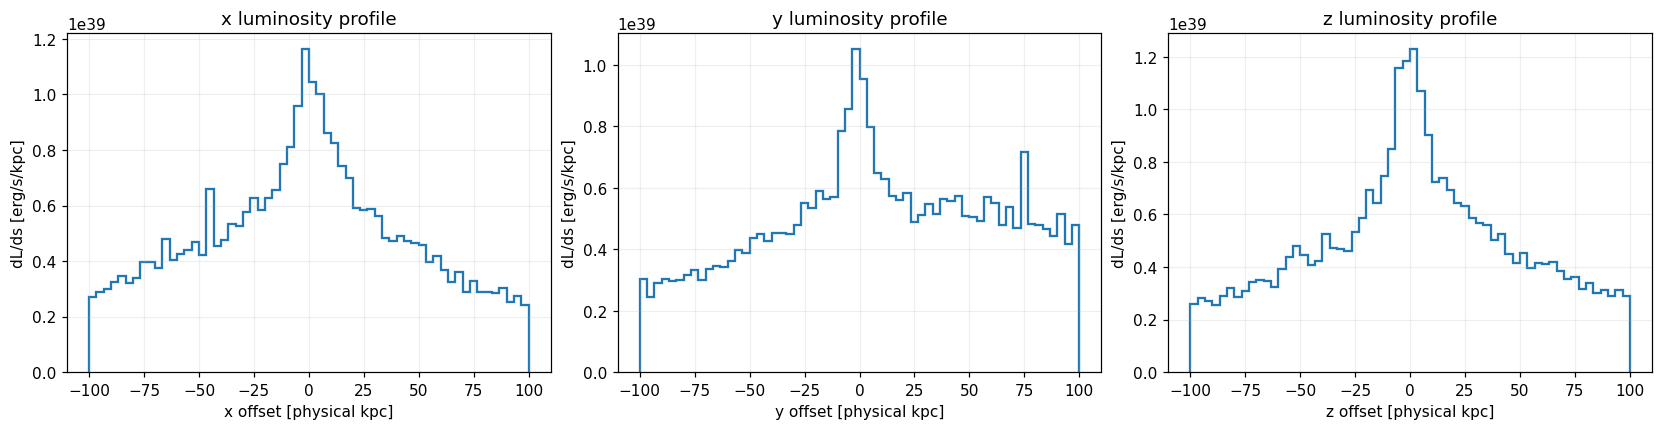

In [5]:
axis_luminosity = {
    "x": cube.sum(axis=(0, 1)),
    "y": cube.sum(axis=(0, 2)),
    "z": cube.sum(axis=(1, 2)),
}
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), constrained_layout=True)
for ax, axis in zip(axs, "xyz"):
    profile = axis_luminosity[axis] / widths[axis]
    np.testing.assert_allclose(np.sum(profile * widths[axis]), total_L, rtol=1e-10, atol=0)
    ax.stairs(profile, edges[axis], color="tab:blue", linewidth=1.5)
    ax.set(xlabel=f"{axis} offset [physical kpc]", ylabel="dL/ds [erg/s/kpc]",
           title=f"{axis} luminosity profile")
    ax.grid(alpha=0.2)
finish_figure(fig, "axis_profiles")


## 5. Three-dimensional radial profile and enclosed luminosity

Use the largest sphere centered on `PROFILE_CENTER_OFFSET_KPC` that fits completely inside the saved rectangular grid. This prevents an incomplete outer shell from being presented as a full halo measurement.

Voxels are assigned to shells by their centers; boundary voxels are not subdivided. The shell emissivity is `sum(L_voxel) / sum(V_voxel)`, including zero-luminosity voxels. Empty shells are reported and have no defined average. The cumulative fraction below uses the **whole saved cube luminosity** as its denominator.


Complete-sphere radius: 100 physical kpc
Empty radial bins: 0 / 15
Luminosity assigned inside sphere: 6.896197e+40 erg/s
Fraction of saved cube luminosity in sphere: 68.626%


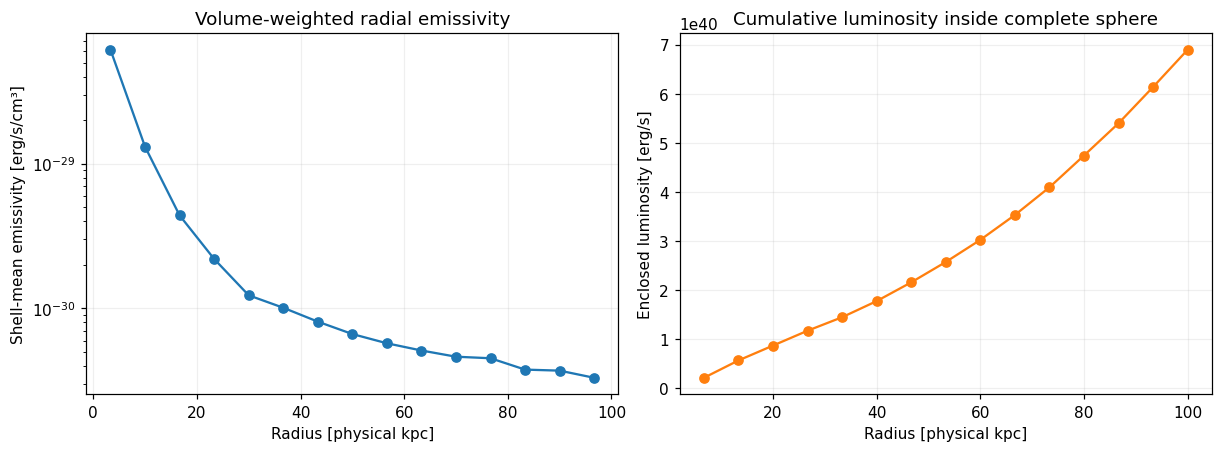

In [6]:
profile_center = np.asarray(PROFILE_CENTER_OFFSET_KPC, dtype=float)
if profile_center.shape != (3,) or not np.all(np.isfinite(profile_center)):
    raise ValueError("PROFILE_CENTER_OFFSET_KPC must contain three finite coordinates.")
if not isinstance(N_RADIAL_BINS, (int, np.integer)) or N_RADIAL_BINS < 1:
    raise ValueError("N_RADIAL_BINS must be a positive integer.")
r_complete = min(min(profile_center[i] - edges[axis][0],
                     edges[axis][-1] - profile_center[i]) for i, axis in enumerate("xyz"))
if r_complete <= 0:
    raise ValueError("Radial-profile center must be strictly inside the grid.")
zz, yy, xx = np.meshgrid(centers["z"], centers["y"], centers["x"], indexing="ij")
radius = np.sqrt((xx - profile_center[0])**2 + (yy - profile_center[1])**2
                 + (zz - profile_center[2])**2)
r_edges = np.linspace(0, r_complete, N_RADIAL_BINS + 1)
r_centers = 0.5 * (r_edges[:-1] + r_edges[1:])
shell_L, _ = np.histogram(radius.ravel(), bins=r_edges, weights=cube.ravel())
shell_V, _ = np.histogram(radius.ravel(), bins=r_edges, weights=voxel_volume.ravel())
shell_epsilon = np.divide(shell_L, shell_V, out=np.full(shell_L.shape, np.nan), where=shell_V > 0)
cumulative_L = np.cumsum(shell_L)
inside_sphere = radius <= r_complete
np.testing.assert_allclose(shell_L.sum(), cube[inside_sphere].sum(), rtol=1e-10, atol=0)
print(f"Complete-sphere radius: {r_complete:g} physical kpc")
print(f"Empty radial bins: {np.count_nonzero(shell_V == 0)} / {N_RADIAL_BINS}")
print(f"Luminosity assigned inside sphere: {shell_L.sum():.6e} erg/s")
if total_L > 0:
    print(f"Fraction of saved cube luminosity in sphere: {shell_L.sum() / total_L:.3%}")
fig, axs = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axs[0].plot(r_centers, shell_epsilon, marker="o", color="tab:blue")
if np.any(shell_epsilon > 0):
    axs[0].set_yscale("log")
axs[0].set(xlabel="Radius [physical kpc]", ylabel="Shell-mean emissivity [erg/s/cm³]",
           title="Volume-weighted radial emissivity")
axs[1].plot(r_edges[1:], cumulative_L, marker="o", color="tab:orange")
axs[1].set(xlabel="Radius [physical kpc]", ylabel="Enclosed luminosity [erg/s]",
           title="Cumulative luminosity inside complete sphere")
for ax in axs:
    ax.grid(alpha=0.2)
finish_figure(fig, "radial_profiles")


## 6. Emitting-voxel distribution and luminosity concentration

The histogram includes only positive-emissivity voxels, with the excluded zero-voxel count printed. The concentration curve ranks **all** voxels by emissivity and uses their actual volumes. It shows what fraction of saved-grid volume contains a given fraction of its luminosity; it is not a gas-mass or particle-count distribution.


Zero-emissivity voxels excluded from logarithmic histogram: 180,115


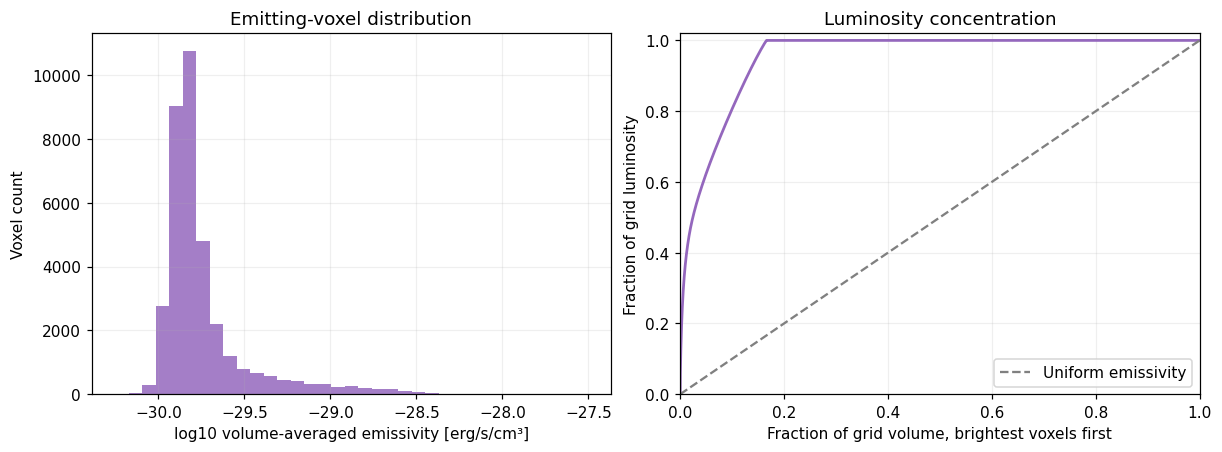

In [7]:
positive_epsilon = emissivity[emissivity > 0]
print(f"Zero-emissivity voxels excluded from logarithmic histogram: "
      f"{cube.size - positive_epsilon.size:,}")
fig, axs = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
if positive_epsilon.size:
    axs[0].hist(np.log10(positive_epsilon), bins=35, color="tab:purple", alpha=0.85)
else:
    axs[0].text(0.5, 0.5, "No emitting voxels", ha="center", transform=axs[0].transAxes)
axs[0].set(xlabel="log10 volume-averaged emissivity [erg/s/cm³]",
           ylabel="Voxel count", title="Emitting-voxel distribution")
if total_L > 0:
    rank = np.argsort(emissivity.ravel())[::-1]
    volume_fraction = np.r_[0.0, np.cumsum(voxel_volume.ravel()[rank]) / voxel_volume.sum()]
    luminosity_fraction = np.r_[0.0, np.cumsum(cube.ravel()[rank]) / total_L]
    axs[1].plot(volume_fraction, luminosity_fraction, color="tab:purple", linewidth=1.8)
    axs[1].plot([0, 1], [0, 1], "--", color="0.5", label="Uniform emissivity")
    axs[1].legend()
else:
    axs[1].text(0.5, 0.5, "Undefined for zero total luminosity", ha="center",
                transform=axs[1].transAxes)
axs[1].set(xlabel="Fraction of grid volume, brightest voxels first",
           ylabel="Fraction of grid luminosity", xlim=(0, 1), ylim=(0, 1.02),
           title="Luminosity concentration")
for ax in axs:
    ax.grid(alpha=0.2)
finish_figure(fig, "emission_distribution")


## Interpretation and next checks

- These statistics describe the saved aperture. Use the coverage summary before quoting a halo-wide luminosity.
- Saved emissivity is diluted by the complete voxel volume; empty pixels do not prove an absence of gas. This file has no gas-mass, temperature, or metallicity cube.
- The archive records the line, table type, and input filenames, but may not preserve every Cloudy abundance/radiation assumption or the number of clipped particles. Consult the run configuration and Slurm log for those details.
- For the current point-deposition cube, small-scale patterns depend on bin size and grid alignment. Any Gaussian smoothing used for display should be labeled separately.
- Set `SAVE_FIGURES=True` and rerun plotting cells to export PNGs. To analyze another PPP run, set `CUBE_PATH` and rerun the notebook.
